# **03. Prediksi dan Submission**

Alur: memverifikasi akurasi model final pada data validasi, membuat `submissions/submission.csv`, memeriksa distribusi prediksi sebagai sanity check, lalu mengunggah ke Kaggle.

In [1]:
import sys
sys.path.append("..")

from dataclasses import replace

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from scripts.config import Config, CLASS_NAMES
from scripts.dataset import make_eval_loader
from scripts.model import load_model_from_checkpoint
from scripts.predict import ensemble_probs, write_submission
from scripts.utils import get_device

cfg = Config()
device = get_device()
test = pd.read_csv(cfg.test_csv)

## 1. Verifikasi model final pada validasi
Akurasi model final dihitung ulang pada data validasi dari checkpoint yang tersimpan, untuk memastikan checkpoint yang dipakai sama dengan yang dilaporkan di notebook 02.

In [2]:
checkpoints = [
    cfg.checkpoint_dir / "resnet18_160_best.pt",
    # cfg.checkpoint_dir / "mobilenet_v3_large_160_best.pt",   # aktifkan jika sudah dilatih
]

def val_probs(ckpt_path, cfg, device):
    """Probabilitas softmax satu checkpoint pada data validasinya.

    Args:
        ckpt_path: Path checkpoint.
        cfg: Objek Config.
        device: Device komputasi.

    Returns:
        Tuple (probabilitas (N, 16), label benar (N,), indeks validasi).
    """
    model, meta = load_model_from_checkpoint(ckpt_path, device)
    cfg_l = replace(cfg, image_size=meta["image_size"])
    all_labels = pd.read_csv(cfg.train_csv)["label"].to_numpy()
    loader = make_eval_loader(cfg_l, meta["val_idx"], all_labels)
    out = []
    with torch.no_grad():
        for x, _ in loader:
            out.append(torch.softmax(model(x.to(device)), dim=1).cpu().numpy())
    return np.concatenate(out), all_labels[meta["val_idx"]], meta["val_idx"]

results = [val_probs(p, cfg, device) for p in checkpoints]
assert all(np.array_equal(results[0][2], r[2]) for r in results), "Split validasi berbeda antar checkpoint"
y = results[0][1]

rows = [(p.name, (pr.argmax(1) == y).mean()) for p, (pr, _, _) in zip(checkpoints, results)]
if len(results) > 1:
    rows.append(("ensemble (rata-rata probabilitas)",
                 (np.mean([r[0] for r in results], axis=0).argmax(1) == y).mean()))
print(pd.DataFrame(rows, columns=["model", "akurasi_validasi"]).round(4).to_string(index=False))

               model  akurasi_validasi
resnet18_160_best.pt            0.8277


**Interpretasi:** 

Akurasi validasi checkpoint `resnet18_160_best.pt` adalah 0,8277, sama persis dengan nilai yang tercatat saat training (epoch 7). Ini menegaskan dua hal: checkpoint yang dipakai untuk prediksi adalah model terbaik, dan split validasi dapat direproduksi karena indeksnya tersimpan di dalam checkpoint. Hanya satu model yang dievaluasi sehingga tidak ada perbandingan atau ensemble. Model tunggal dipilih karena keterbatasan waktu dan komputasi CPU. Galat standar akurasi pada 4.801 sampel validasi sekitar 0,5 poin.

## 2. Prediksi data uji

Pastikan cache test sudah dibuat (`python -m scripts.preprocess --size 160`). `final_checkpoints` diisi sesuai keputusan di bagian 1: satu checkpoint, atau semuanya untuk ensemble.

In [3]:
final_checkpoints = checkpoints   # ubah ke satu checkpoint jika ensemble tidak lebih baik
probs = ensemble_probs(final_checkpoints, cfg, device)
sub = write_submission(test["id"], probs.argmax(axis=1), cfg.submission_dir / "submission.csv",
                       cfg.sample_submission_csv)
sub.head()

Prediksi dengan resnet18_160_best.pt (val acc 0.8277)


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,6
3,test_00004,11
4,test_00005,13


**Interpretasi:** 

Prediksi dibuat dengan checkpoint ResNet18 (val acc 0,8277). Fungsi `write_submission` lolos tanpa error, artinya nama kolom, jumlah baris (7.994), urutan id terhadap `sample_submission.csv`, dan rentang label 0 sampai 15 sudah valid. Lima baris pertama berurutan dari `test_00001` sampai `test_00005` dengan label 0 (advertisement), 0 (advertisement), 6 (invoice), 11 (questionnaire), dan 13 (scientific_publication). Label data uji tidak tersedia, sehingga ketepatan prediksi ini baru diketahui dari skor Kaggle.

## 3. Sanity check distribusi prediksi

                         train  prediksi_test  selisih
advertisement           0.0629         0.0671   0.0042
budget                  0.0626         0.0573  -0.0053
email                   0.0629         0.0630   0.0001
file_folder             0.0632         0.0696   0.0064
form                    0.0627         0.0615  -0.0011
handwritten             0.0633         0.0650   0.0017
invoice                 0.0619         0.0633   0.0014
letter                  0.0616         0.0619   0.0003
memo                    0.0623         0.0672   0.0049
news_article            0.0616         0.0557  -0.0059
presentation            0.0622         0.0660   0.0038
questionnaire           0.0609         0.0555  -0.0053
resume                  0.0634         0.0614  -0.0020
scientific_publication  0.0642         0.0629  -0.0013
scientific_report       0.0625         0.0617  -0.0008
specification           0.0618         0.0608  -0.0010


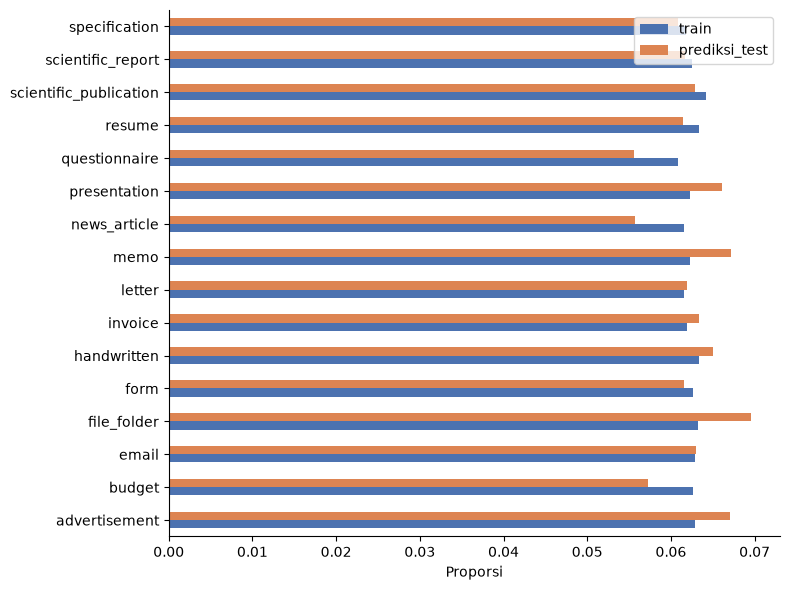

In [4]:
train = pd.read_csv(cfg.train_csv)
cmp = pd.DataFrame({"train": train["label"].value_counts(normalize=True).sort_index(),
                    "prediksi_test": sub["label"].value_counts(normalize=True).sort_index()}).fillna(0)
cmp.index = [CLASS_NAMES[i] for i in cmp.index]
print(cmp.assign(selisih=cmp["prediksi_test"] - cmp["train"]).round(4))

ax = cmp.plot.barh(figsize=(8, 6), color=["#4C72B0", "#DD8452"])
ax.set_xlabel("Proporsi")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(cfg.figures_dir / "test_prediction_distribution.png", dpi=150)
plt.show()

**Interpretasi:** 

Proporsi prediksi pada data uji mendekati proporsi data latih (sekitar 6,25 persen per kelas). Selisih terbesar hanya 0,0064 (file_folder, +0,64 poin persentase, setara sekitar 51 gambar dari 7.994) dan yang terkecil negatif adalah news_article (-0,0059). Tidak ada kelas yang hilang atau mendominasi, sehingga tidak ada indikasi bug urutan atau pergeseran distribusi yang besar.

Arah penyimpangannya konsisten dengan pola yang terlihat pada validasi (notebook 02). Kelas yang pada validasi memiliki recall lebih tinggi daripada precision cenderung diprediksi berlebih di data uji: file_folder (+0,0064), memo (+0,0049), presentation (+0,0038), dan advertisement (+0,0042). Kelas yang recall-nya lebih rendah daripada precision cenderung kurang diprediksi: news_article (-0,0059) dan questionnaire (-0,0053). Dugaan bahwa presentation kebanyakan diprediksi terbukti ringan (6,60 persen berbanding 6,22 persen), sedangkan scientific_report hampir tidak menyimpang (-0,0008), tidak sekuat dugaan. Budget (-0,0053) kurang diprediksi tanpa penjelasan dari pola precision dan recall di validasi.

Catatan: proporsi data uji sebenarnya tidak diketahui, jadi tabel ini membandingkan prediksi dengan proporsi data latih sebagai acuan, bukan dengan nilai sebenarnya. Selisih sebesar ini juga mendekati noise statistik, sehingga polanya jangan ditafsirkan berlebihan.

## 4. Unggah ke Kaggle

`submissions/submission.csv` diunggah ke halaman Submit Predictions. Public score ResNet18 (input 160 piksel) adalah 0,83228, sedangkan akurasi validasi 0,8277. Selisihnya sekitar 0,5 poin, masih dalam rentang noise statistik, sehingga validasi lokal merupakan estimasi yang cukup andal dan tidak ada indikasi pergeseran distribusi antara data latih dan uji. Private score dilaporkan setelah kompetisi ditutup.